# Machine Learning Practicals: KNN, K-Means and Hierarchical Clustering

**Files required in this notebook's folder:** `diabetes.csv` and `sales_data_sample.csv`.

The included CSV files are synthetic practice datasets created for learning and are not real patient or company records.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay

from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

%matplotlib inline

## 2. KNN Classification on diabetes.csv

### 2.1 Load and view the dataset

In [2]:
diabetes_df = pd.read_csv('diabetes.csv')
print('Shape:', diabetes_df.shape)
display(diabetes_df.head())
print('Missing values:\n', diabetes_df.isnull().sum())
print('Target counts:\n', diabetes_df['Outcome'].value_counts())

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,4,103.2,70.9,17.5,0.0,30.2,0.398,25,0
1,5,87.4,84.1,17.3,71.6,25.7,0.233,34,0
2,5,125.3,68.3,24.2,102.4,33.4,0.773,43,1
3,3,0.0,69.4,30.5,163.0,30.6,0.780,26,0
4,5,55.0,60.3,36.3,0.0,42.8,0.727,54,0


Missing values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Target counts:
 Outcome
0    508
1    260
Name: count, dtype: int64


### 2.2 Separate input features and target

In [3]:
X = diabetes_df.drop('Outcome', axis=1).copy()
y = diabetes_df['Outcome'].copy()

# In this commonly used Pima-style format, zero in these measurement columns
# can represent an unrecorded measurement. Replace those zeros with NaN.
zero_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for column in zero_columns:
    X[column] = X[column].replace(0, np.nan)

print('Features shape:', X.shape)
print('Target shape:', y.shape)

Features shape: (768, 8)
Target shape: (768,)


### 2.3 Split training and testing data

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training records:', X_train.shape[0])
print('Testing records:', X_test.shape[0])

Training records: 614
Testing records: 154


### 2.4 Train the KNN model

In [5]:
knn_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)
print('KNN model training completed.')

KNN model training completed.


### 2.5 Predict test data

In [6]:
y_pred = knn_model.predict(X_test)
print('Predicted values:', y_pred[:20])
print('Actual values:   ', y_test.to_numpy()[:20])

Predicted values: [0 1 0 1 0 0 1 0 0 0 0 1 0 0 1 1 0 1 0 0]
Actual values:    [0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0]


### 2.6 Confusion matrix

Confusion Matrix:
 [[83 19]
 [32 20]]


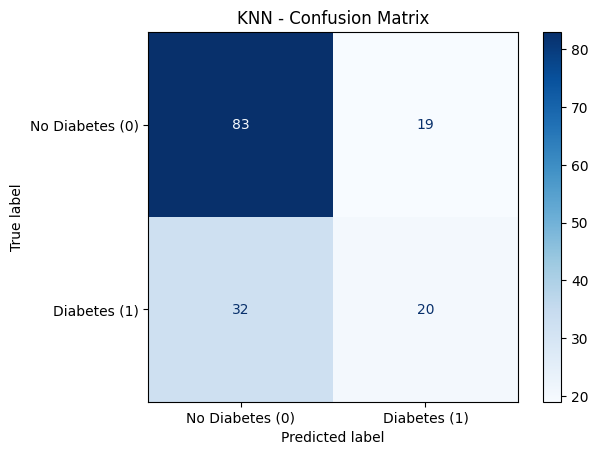

In [7]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print('Confusion Matrix:\n', cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Diabetes (0)', 'Diabetes (1)']
).plot(cmap='Blues')
plt.title('KNN - Confusion Matrix')
plt.show()

### 2.7 Accuracy, error rate, precision and recall

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print(f'Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)')
print(f'Error Rate: {error_rate:.4f} ({error_rate * 100:.2f}%)')
print(f'Precision : {precision:.4f}')
print(f'Recall    : {recall:.4f}')

## 3. K-Means Clustering on sales_data_sample.csv

### 3.1 Load and view the dataset

In [ ]:
sales_df = pd.read_csv('sales_data_sample.csv', encoding='latin1')
print('Shape:', sales_df.shape)
display(sales_df.head())
print('Columns:', sales_df.columns.tolist())

### 3.2 Select numerical features and clean rows

In [ ]:
sales_features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']

X_sales = sales_df[sales_features].apply(pd.to_numeric, errors='coerce')
valid_rows = X_sales.dropna().index
X_sales = X_sales.loc[valid_rows]
sales_clean = sales_df.loc[valid_rows].copy()

print('Rows used for clustering:', X_sales.shape[0])
display(X_sales.head())

### 3.3 Apply feature scaling

In [ ]:
sales_scaler = StandardScaler()
X_sales_scaled = sales_scaler.fit_transform(X_sales)
print('Scaled data shape:', X_sales_scaled.shape)

### 3.4 Elbow Method

In [ ]:
wcss = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_sales_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

### 3.5 Apply K-Means using the elbow value

After viewing the graph, change `optimal_k` below to the elbow point you identify. The starting value is 3 for this practice dataset.

In [ ]:
optimal_k = 3  # Change this value after inspecting the Elbow graph

kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

sales_clean['KMeans_Cluster'] = kmeans_model.fit_predict(X_sales_scaled)
print(sales_clean[['KMeans_Cluster'] + sales_features].head())

print('Cluster-wise average values:')
display(sales_clean.groupby('KMeans_Cluster')[sales_features].mean().round(2))

### 3.6 Plot K-Means clusters

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(
    sales_clean['QUANTITYORDERED'],
    sales_clean['SALES'],
    c=sales_clean['KMeans_Cluster'],
    cmap='viridis',
    alpha=0.7
)
plt.title('K-Means Clusters: Quantity Ordered vs Sales')
plt.xlabel('Quantity Ordered')
plt.ylabel('Sales')
plt.show()

## 4. Hierarchical (Agglomerative) Clustering on sales_data_sample.csv

### 4.1 Take a sample for dendrogram and hierarchical clustering

In [ ]:
# Hierarchical clustering can require substantial memory and processing time.
# A reproducible sample is used if the dataset has more than 400 rows.
max_hierarchical_rows = 400
if len(X_sales) > max_hierarchical_rows:
    X_hier = X_sales.sample(n=max_hierarchical_rows, random_state=42)
else:
    X_hier = X_sales.copy()

hier_scaler = StandardScaler()
X_hier_scaled = hier_scaler.fit_transform(X_hier)
print('Rows used for hierarchical clustering:', len(X_hier))

### 4.2 Create dendrogram

In [ ]:
linkage_matrix = linkage(X_hier_scaled, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Merged data points / clusters')
plt.ylabel('Distance')
plt.show()

### 4.3 Apply Agglomerative Clustering

In [ ]:
hierarchical_k = optimal_k  # You may change this after inspecting the dendrogram

hierarchical_model = AgglomerativeClustering(
    n_clusters=hierarchical_k,
    linkage='ward'
)

hierarchical_labels = hierarchical_model.fit_predict(X_hier_scaled)
hierarchical_result = sales_df.loc[X_hier.index].copy()
hierarchical_result['Hierarchical_Cluster'] = hierarchical_labels

print(hierarchical_result[['Hierarchical_Cluster'] + sales_features].head())
print('Cluster-wise average values:')
display(hierarchical_result.groupby('Hierarchical_Cluster')[sales_features].mean().round(2))

## 5. Save output files

In [ ]:
sales_clean.to_csv('sales_kmeans_clustered.csv', index=False)
hierarchical_result.to_csv('sales_hierarchical_clustered.csv', index=False)
print('Saved: sales_kmeans_clustered.csv')
print('Saved: sales_hierarchical_clustered.csv')

## 6. Final result

In [ ]:
print('KNN Accuracy :', round(accuracy * 100, 2), '%')
print('KNN Error Rate:', round(error_rate * 100, 2), '%')
print('KNN Precision:', round(precision, 4))
print('KNN Recall   :', round(recall, 4))
print('K-Means clusters:', optimal_k)
print('Hierarchical clusters:', hierarchical_k)
print('Both clustering outputs have been saved.')